# 04. 상담 예제 3 — "해외 결제 승인 알림을 확인하고 싶어요" (risk 검증 sub-flow)

세 번째 상담 예제입니다. tool은 성공하지만 결과에 **fraud/AML 모니터링 flag**가 붙어 있어, D7(리스크 점검)이 이를 감지하면 **KYC 재검증 tool 실행 -> D8(통과 여부 판정)** 을 거쳐 종결하는 조건부 sub-flow를 돕니다.

후반부에는 **guardrail 과차단**을 양쪽 backend로 직접 체험합니다 — 같은 의미의 피해 신고 문구가 Haiku에서는 정상 처리되고, SGLang(Qwen3-VL-8B)에서는 접수 단계에서 차단되는 것을 비교합니다.

In [1]:
import sys; from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # ws_common 경로 (repo 내 상대 위치)
import ws_common as W
graphs, client = W.make_graphs()
sc = W.SCENARIOS[3]
print("시나리오:", sc["title"])
print("고객 질문:", sc["question"])
print("script:", sc["script"])   # risk_flag: True, kyc_result: verified

시나리오: 이상거래 모니터링 flag -> KYC sub-flow
고객 질문: 카드 끝자리 7712로 해외 결제(USD 1,284, LUXE GADGETS) 승인이 됐다는 알림을 받았는데, 이 거래를 확인하고 싶어요.
script: {'vague': False, 'clarify_reply': None, 'no_info_reply': '지금 알려드릴 수 있는 정보는 그게 전부예요.', 'tool_outcomes': ['success'], 'risk_flag': True, 'kyc_result': 'verified'}


## 전체 workflow에서 이 시나리오의 위치

이번 시나리오가 지나는 경로(빨간 테두리): tool 성공 결과에 모니터링 flag가 있어 **risk_check -> kyc_verify(D8)** sub-flow를 지나 종결합니다. 금융권의 "고위험 거래는 신원 재검증 후 종결" 절차가 그래프에 들어온 형태입니다.

배정 상담팀(빨간 표시): **card_security(분실/도난/보안)** — 이상 결제 확인·차단 문맥입니다. 실행에서 모델이 cards를 고르는 경우도 있으니 STEP 출력의 D2 판정과 비교해 보세요.
> 참고: 이 다이어그램은 실행되는 LangGraph에서 자동 생성된 것이 아니라, `ws_common.py`의 한글 캡션 사전(`KO_NODES`/`KO_EDGES`)을 노드 이름 기준으로 그린 **시각화 전용 그림**입니다 (상세 설명: `[KR]_01_build_agent.ipynb` 참조).


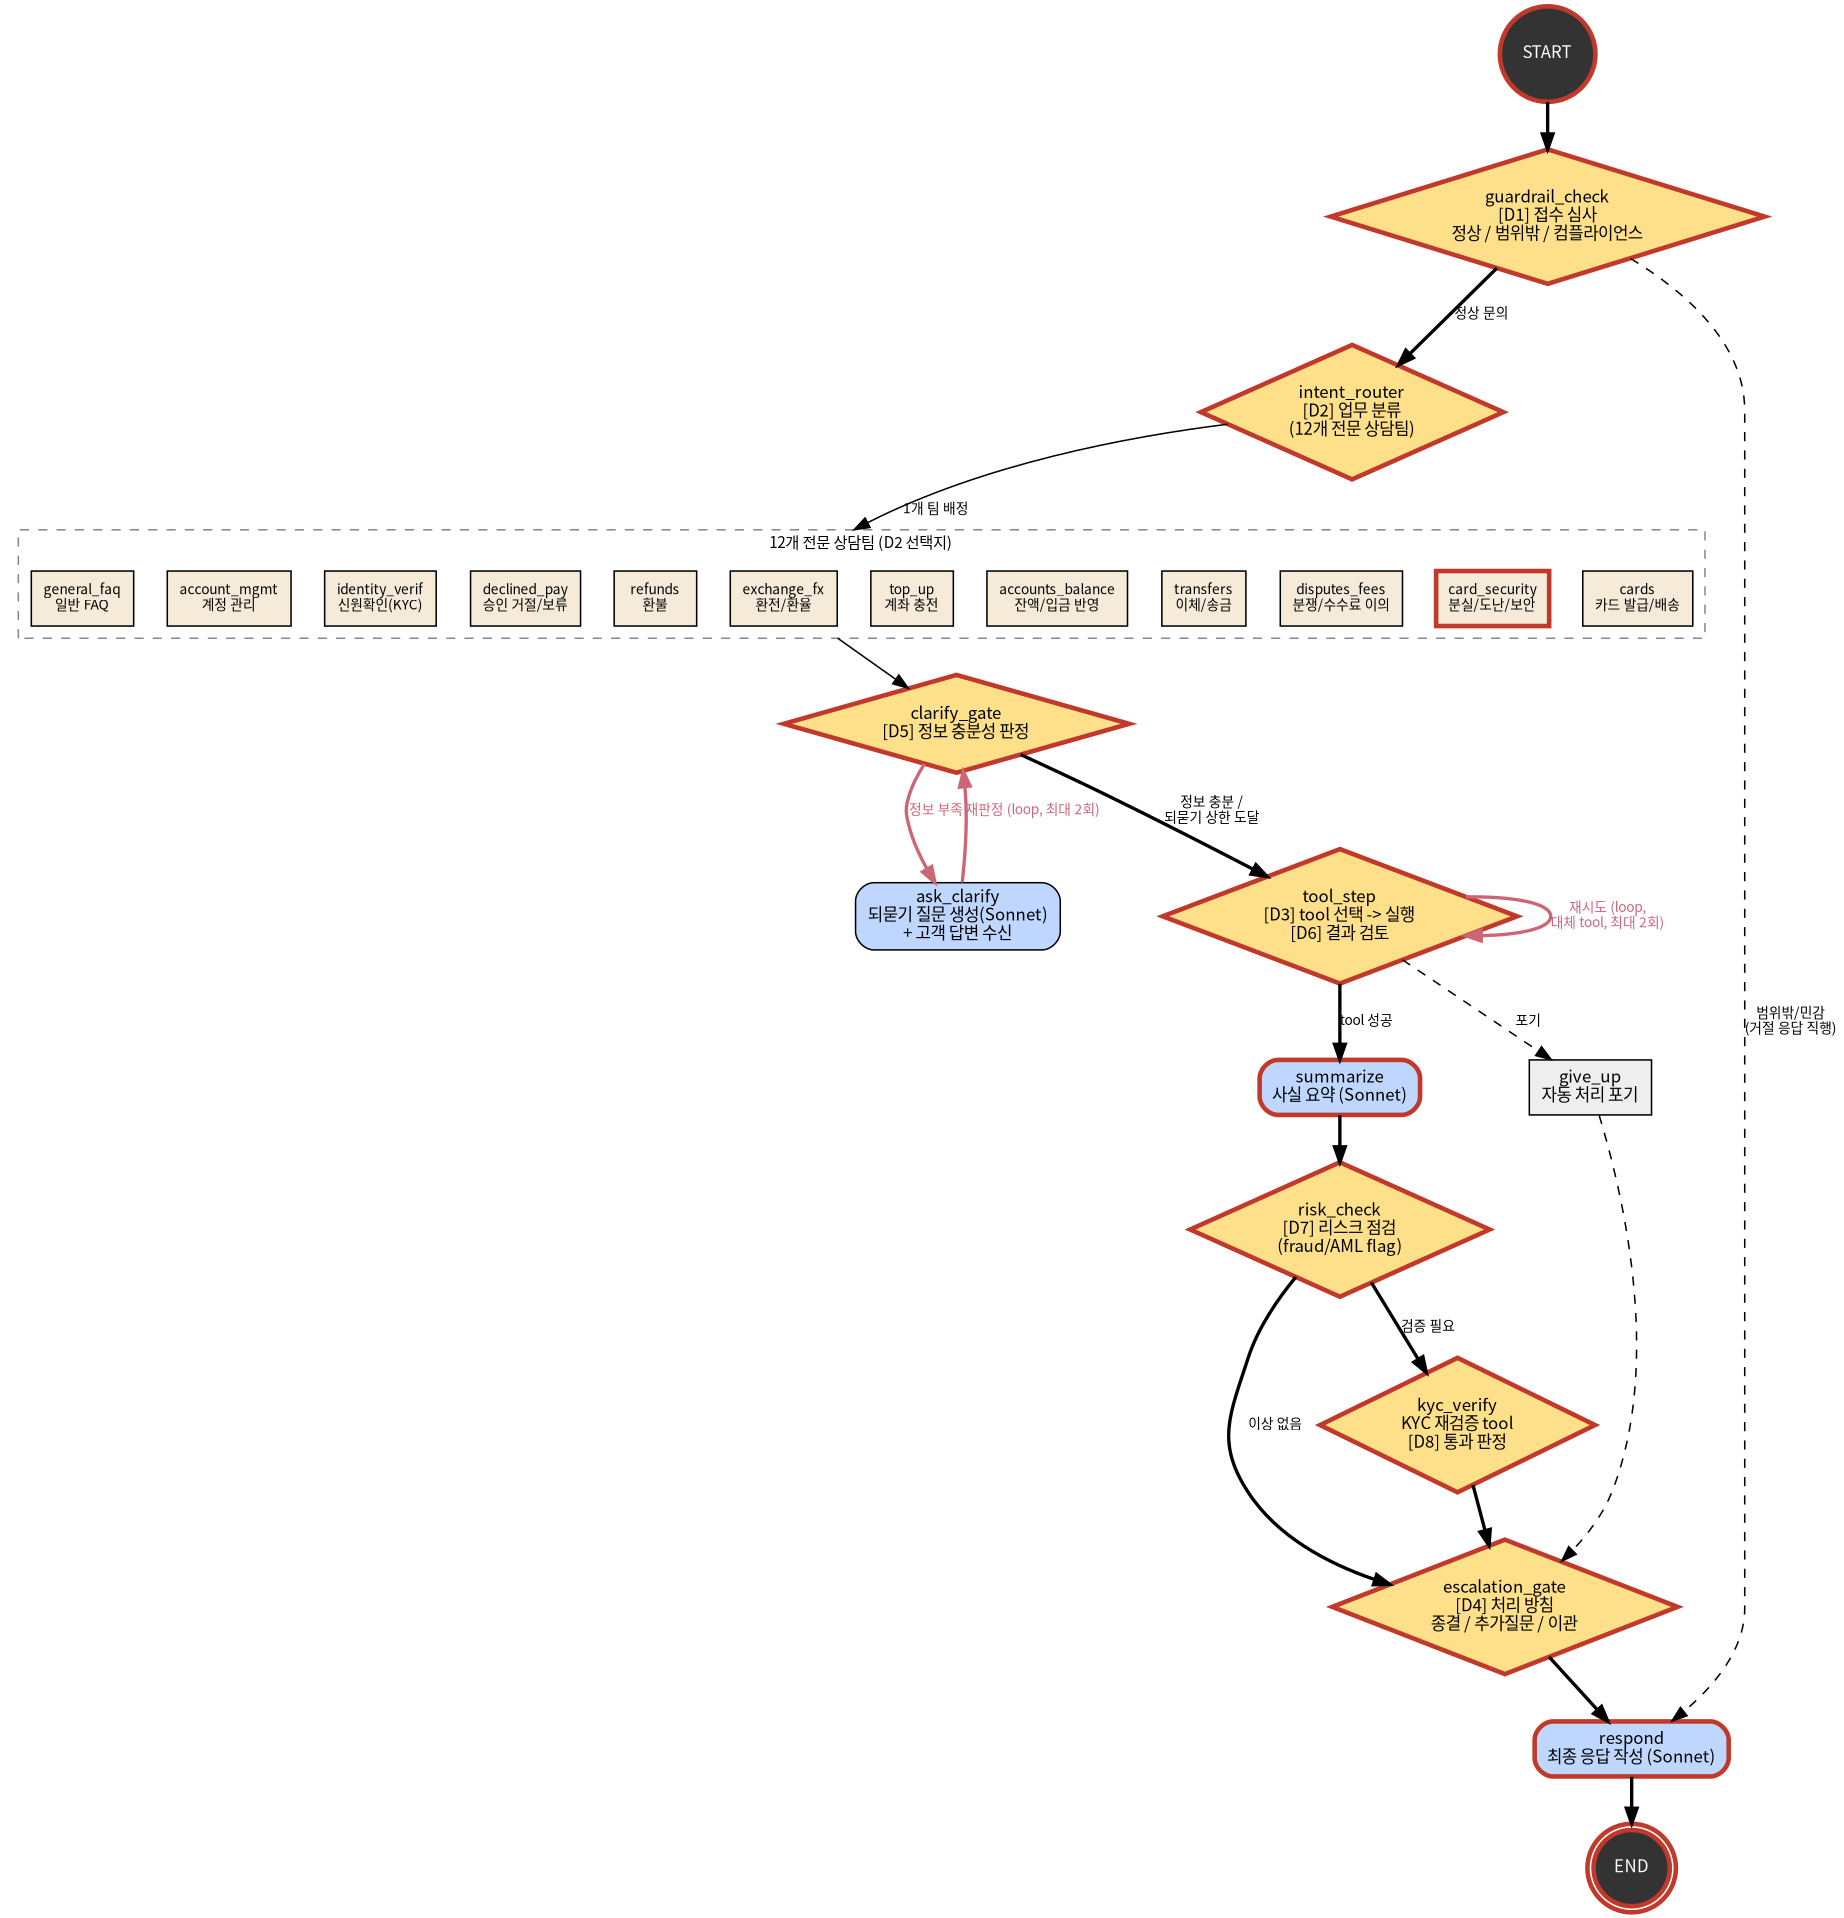

In [2]:
W.draw_graph(highlight=W.SCENARIO_PATHS[3], show_teams=True, width=760)

## ① Haiku 4.5 판단으로 실행

STEP 출력에서 risk_check가 `needs_verification`을 판정한 뒤 **kyc_verify 노드가 추가로 실행**되는 것을 확인하세요.

In [3]:
res_haiku = W.run_verbose(graphs["Haiku"], sc["question"], sc["script"], "Haiku")


[Haiku] 고객: 카드 끝자리 7712로 해외 결제(USD 1,284, LUXE GADGETS) 승인이 됐다는 알림을 받았는데, 이 거래를 확인하고 싶어요.



STEP 1 ▶ guardrail_check — D1 접수 심사: 정상 문의 / 범위 밖 / compliance 위반
      판정[D1] -> in_scope   (935ms)



STEP 2 ▶ intent_router — D2 업무 분류: 12개 전문 상담 category 중 선택
      판정[D2] -> cards   (778ms)



STEP 3 ▶ clarify_gate — D5 정보 충분성 판정: 바로 처리 가능한가, 되물어야 하는가
      판정[D5] -> info_sufficient   (784ms)



STEP 4 ▶ tool_step — D3 tool 선택 -> tool 실행 -> D6 결과 검토(성공/재시도/포기)
      판정[D3] -> card_troubleshoot   (626ms)
      tool 실행: card_troubleshoot   (0.0ms)
      판정[D6] -> goal_met   (1,899ms)



STEP 5 ▶ summarize — Sonnet이 tool 결과를 고객 응대용 사실 요약으로 정리
      생성(Sonnet 4.5)   (3,552ms)
      요약(첫 줄): Based on the tool result, here are the key facts for the customer:



STEP 6 ▶ risk_check — D7 리스크 점검: fraud/AML 모니터링 flag 유무
      판정[D7] -> needs_verification   (697ms)



STEP 7 ▶ kyc_verify — KYC 재검증 tool 실행 -> D8 통과 여부 판정
      tool 실행: run_kyc_check   (0.0ms)
      판정[D8] -> verified   (719ms)



STEP 8 ▶ escalation_gate — D4 처리 방침: 종결 / 추가 질문 / 상담사 이관
      판정[D4] -> human_handoff   (1,776ms)



STEP 9 ▶ respond — Sonnet이 최종 고객 응답 작성
      생성(Sonnet 4.5)   (5,527ms)
      --- 최종 응답 ---
      안녕하세요,
      
      말씀하신 카드 끝자리 7712번의 USD 1,284 LUXE GADGETS 거래를 확인했습니다.
      
      해당 거래는 비정상적인 지역 또는 금액 패턴으로 인해 저희 사기 방지 시스템에서 모니터링 플래그가 발생했습니다. 고객님의 자산 보호를 위해 이 건은 전문 상담원에게 전달되었습니다.
      
      **참조번호: REF-ws-Haiku-27599**
      
      전문 상담원이 1영업일 내에 연락드려 거래 내역을 상세히 확인하고, 필요시 추가 보안 조치를 안내해 드릴 예정입니다. 
      
      고객님의 계좌 안전을 최우선으로 하고 있으니 양해 부탁드립니다.
      
      감사합니다.

>>> [Haiku] 결정 8회 합계 8,213ms | 생성 9,079ms | e2e 17,301ms


## ② SGLang(Qwen3-VL-8B) 판단으로 실행

In [4]:
res_sglang = W.run_verbose(graphs["SGLang"], sc["question"], sc["script"], "SGLang")


[SGLang] 고객: 카드 끝자리 7712로 해외 결제(USD 1,284, LUXE GADGETS) 승인이 됐다는 알림을 받았는데, 이 거래를 확인하고 싶어요.

STEP 1 ▶ guardrail_check — D1 접수 심사: 정상 문의 / 범위 밖 / compliance 위반
      판정[D1] -> in_scope   (54ms, confidence 0.910)

STEP 2 ▶ intent_router — D2 업무 분류: 12개 전문 상담 category 중 선택
      판정[D2] -> card_security   (35ms, confidence 0.991)

STEP 3 ▶ clarify_gate — D5 정보 충분성 판정: 바로 처리 가능한가, 되물어야 하는가
      판정[D5] -> info_sufficient   (34ms, confidence 1.000)

STEP 4 ▶ tool_step — D3 tool 선택 -> tool 실행 -> D6 결과 검토(성공/재시도/포기)
      판정[D3] -> freeze_card   (33ms, confidence 0.999)
      tool 실행: freeze_card   (0.0ms)
      판정[D6] -> goal_met   (35ms, confidence 1.000)



STEP 5 ▶ summarize — Sonnet이 tool 결과를 고객 응대용 사실 요약으로 정리
      생성(Sonnet 4.5)   (4,093ms)
      요약(첫 줄): Based on the tool result, here are the key resolution facts:

STEP 6 ▶ risk_check — D7 리스크 점검: fraud/AML 모니터링 flag 유무
      판정[D7] -> needs_verification   (38ms, confidence 1.000)

STEP 7 ▶ kyc_verify — KYC 재검증 tool 실행 -> D8 통과 여부 판정
      tool 실행: run_kyc_check   (0.0ms)
      판정[D8] -> verified   (36ms, confidence 1.000)

STEP 8 ▶ escalation_gate — D4 처리 방침: 종결 / 추가 질문 / 상담사 이관
      판정[D4] -> human_handoff   (35ms, confidence 0.995)



STEP 9 ▶ respond — Sonnet이 최종 고객 응답 작성
      생성(Sonnet 4.5)   (6,173ms)
      --- 최종 응답 ---
      안녕하세요,
      
      고객님의 카드 보안을 위해 해당 거래를 확인한 결과, **비정상적인 거래 패턴이 감지**되어 7712 카드를 **즉시 정지 조치** 완료했습니다 (참조번호: REF-ws-SGLang-27616).
      
      USD 1,284 LUXE GADGETS 거래는 사기 방지 시스템에서 의심 거래로 분류되었습니다.
      
      전문 상담원이 **사기 거래 조사 및 카드 재발급 절차**를 안내해 드리겠습니다. 1-2 영업일 내 담당자가 연락드릴 예정이며, 본인 확인 후 상세한 거래 내역을 검토하겠습니다.
      
      불편을 드려 죄송하며, 신속하게 처리하겠습니다.
      
      감사합니다.

>>> [SGLang] 결정 8회 합계 299ms | 생성 10,266ms | e2e 10,571ms


## ③ 수행시간 비교

In [5]:
W.compare(res_haiku, res_sglang)

| 지표 | Haiku | SGLang | 배수(Haiku/SGLang) |
|---|---:|---:|---:|
| 결정 횟수 | 8 | 8 | |
| **결정 latency 합계** | **8,213ms** | **299ms** | **27.5x** |
| 생성(LLM) latency | 9,079ms | 10,266ms | **0.9x** |
| e2e | 17,301ms | 10,571ms | **1.6x** |

**결정 계층 속도 차이: 27.5x** (e2e 단축 6,730ms)

**결정별 latency**

| 노드 | 결정 | Haiku | SGLang | 배수 | 판정 label |
|---|---|---:|---:|---:|---|
| guardrail_check | D1 | 935ms | 54ms | **17.4x** | in_scope (동일) |
| intent_router | D2 | 778ms | 35ms | **22.5x** | Haiku=cards / SGLang=card_security |
| clarify_gate | D5 | 784ms | 34ms | **23.4x** | info_sufficient (동일) |
| tool_select | D3 | 626ms | 33ms | **18.9x** | Haiku=card_troubleshoot / SGLang=freeze_card |
| tool_review | D6 | 1,899ms | 35ms | **54.5x** | goal_met (동일) |
| risk_check | D7 | 697ms | 38ms | **18.2x** | needs_verification (동일) |
| kyc_review | D8 | 719ms | 36ms | **20.2x** | verified (동일) |
| escalation_gate | D4 | 1,776ms | 35ms | **50.3x** | human_handoff (동일) |

## ④ (교보재) guardrail 과차단 — 양쪽 backend로 직접 체험

위 시나리오의 질문은 일부러 중립적으로 썼습니다. 이번에는 같은 상황을 고객이 실제로 말할 법한 **피해 신고 문구**로 바꿔 양쪽 arm에 그대로 흘려 봅니다.

- **Haiku arm**: D1이 in_scope로 판정 -> 전체 workflow가 정상 진행됩니다 (KYC까지).
- **SGLang arm**: D1이 sensitive_compliance로 **과차단** -> STEP 2개 만에 거절 응답으로 직행합니다. 정상 고객이 거절당하는 경험이 어떤 것인지 최종 응답을 읽어 보세요.

In [6]:
victim_q = ("방금 제가 쓰지 않은 해외 결제 승인 알림이 왔어요. LUXE GADGETS라는 곳에서 "
            "USD 1,284이 결제됐다고 합니다. 카드 끝자리는 7712예요. 막아주세요.")

res_haiku_v = W.run_verbose(graphs["Haiku"], victim_q, sc["script"], "Haiku(피해 신고 문구)")


[Haiku(피해 신고 문구)] 고객: 방금 제가 쓰지 않은 해외 결제 승인 알림이 왔어요. LUXE GADGETS라는 곳에서 USD 1,284이 결제됐다고 합니다. 카드 끝자리는 7712예요. 막아주세요.



STEP 1 ▶ guardrail_check — D1 접수 심사: 정상 문의 / 범위 밖 / compliance 위반
      판정[D1] -> in_scope   (1,104ms)



STEP 2 ▶ intent_router — D2 업무 분류: 12개 전문 상담 category 중 선택
      판정[D2] -> card_security   (656ms)



STEP 3 ▶ clarify_gate — D5 정보 충분성 판정: 바로 처리 가능한가, 되물어야 하는가
      판정[D5] -> info_sufficient   (1,109ms)



STEP 4 ▶ tool_step — D3 tool 선택 -> tool 실행 -> D6 결과 검토(성공/재시도/포기)
      판정[D3] -> freeze_card   (1,575ms)
      tool 실행: freeze_card   (0.0ms)
      판정[D6] -> goal_met   (730ms)



STEP 5 ▶ summarize — Sonnet이 tool 결과를 고객 응대용 사실 요약으로 정리
      생성(Sonnet 4.5)   (6,056ms)
      요약(첫 줄): **Resolution Facts:**



STEP 6 ▶ risk_check — D7 리스크 점검: fraud/AML 모니터링 flag 유무
      판정[D7] -> needs_verification   (634ms)



STEP 7 ▶ kyc_verify — KYC 재검증 tool 실행 -> D8 통과 여부 판정
      tool 실행: run_kyc_check   (0.0ms)
      판정[D8] -> verified   (652ms)



STEP 8 ▶ escalation_gate — D4 처리 방침: 종결 / 추가 질문 / 상담사 이관
      판정[D4] -> resolve   (930ms)



STEP 9 ▶ respond — Sonnet이 최종 고객 응답 작성
      생성(Sonnet 4.5)   (6,435ms)
      --- 최종 응답 ---
      고객님, 즉시 조치를 취했습니다.
      
      **완료된 조치:**
      • 카드 끝자리 7712번을 긴급 동결했습니다
      • LUXE GADGETS USD 1,284 해외 결제 건에 대한 사기 방지 조치를 완료했습니다
      • 참조번호: REF-ws-Haiku(피해 신고 문구)-27627
      
      해당 거래는 비정상 패턴으로 이미 모니터링 시스템에 포착되었습니다. 
      
      **다음 단계:**
      전문 사기 방지팀이 48시간 내에 연락드려 환불 절차를 안내해 드리겠습니다. 새 카드는 5-7 영업일 내에 등록된 주소로 발송됩니다.
      
      추가 문의사항이 있으시면 참조번호와 함께 언제든지 연락 주시기 바랍니다.

>>> [Haiku(피해 신고 문구)] 결정 8회 합계 7,388ms | 생성 12,492ms | e2e 19,887ms


In [7]:
res_sglang_v = W.run_verbose(graphs["SGLang"], victim_q, sc["script"], "SGLang(피해 신고 문구)")


[SGLang(피해 신고 문구)] 고객: 방금 제가 쓰지 않은 해외 결제 승인 알림이 왔어요. LUXE GADGETS라는 곳에서 USD 1,284이 결제됐다고 합니다. 카드 끝자리는 7712예요. 막아주세요.

STEP 1 ▶ guardrail_check — D1 접수 심사: 정상 문의 / 범위 밖 / compliance 위반
      판정[D1] -> sensitive_compliance   (37ms, confidence 1.000)



STEP 2 ▶ respond — Sonnet이 최종 고객 응답 작성
      생성(Sonnet 4.5)   (6,649ms)
      --- 최종 응답 ---
      고객님, 말씀하신 부정 사용 의심 건을 확인했습니다.
      
      보안 및 규정 준수를 위해 이러한 거래 분쟁 및 카드 차단 요청은 본인 확인 절차를 거쳐 전문 상담원이 직접 처리해야 합니다.
      
      **즉시 조치 방법:**
      - 고객센터 1588-XXXX로 전화 주시거나
      - 모바일 앱 내 '긴급 카드 정지' 기능을 이용해 주세요
      
      신속한 처리를 위해 카드번호 끝 4자리(7712)와 거래 내역을 준비해 주시면 감사하겠습니다.
      
      불편을 드려 죄송합니다.

>>> [SGLang(피해 신고 문구)] 결정 1회 합계 37ms | 생성 6,649ms | e2e 6,688ms


### 표현을 바꿔가며 D1만 비교

문구 3종을 D1에만 넣어 양쪽 판정을 나란히 봅니다. SGLang이 과차단하는 문구에서 **confidence가 1.0으로 포화**되어 있음을 확인하세요 — threshold로도 거를 수 없는 유형입니다.

In [8]:
from IPython.display import Markdown, display
from agent.prompts import D1_QUESTION
from agent.state import D1_CHOICES
from agent.decisions import SGLangDecision, HaikuDecision
from common import BEDROCK_MODEL_IDS, PRICING

sg = SGLangDecision(model="Qwen/Qwen3-VL-8B-Instruct")
hk = HaikuDecision(client, BEDROCK_MODEL_IDS["haiku-4-5"], PRICING["haiku-4-5"])
probes = [
    victim_q,
    "오늘 새벽에 해외 결제 승인 알림이 왔는데 기억에 없는 거래예요. 확인해 주세요.",
    sc["question"],   # 본 시나리오의 중립 문구
]
rows = ["| 문구 | SGLang D1 (confidence) | Haiku D1 |", "|---|---|---|"]
for t in probes:
    r_sg = sg.decide(state_text=t, question=D1_QUESTION, choices=D1_CHOICES, decision_id="d1")
    r_hk = hk.decide(state_text=t, question=D1_QUESTION, choices=D1_CHOICES, decision_id="d1")
    rows.append(f"| {t[:38]}... | {r_sg.label} ({r_sg.confidence:.3f}) | {r_hk.label} |")
display(Markdown("\n".join(rows)))

| 문구 | SGLang D1 (confidence) | Haiku D1 |
|---|---|---|
| 방금 제가 쓰지 않은 해외 결제 승인 알림이 왔어요. LUXE GAD... | sensitive_compliance (1.000) | in_scope |
| 오늘 새벽에 해외 결제 승인 알림이 왔는데 기억에 없는 거래예요. 확... | sensitive_compliance (0.999) | in_scope |
| 카드 끝자리 7712로 해외 결제(USD 1,284, LUXE GAD... | in_scope (0.910) | in_scope |

**관찰 포인트**
- 같은 고객, 같은 상황인데 **표현에 따라** SGLang arm은 접수 단계에서 거절합니다 — 소형 decision model이 한국어 피해 신고 표현을 compliance 위반으로 오독하는 전형적 한계입니다.
- confidence 1.0 포화 때문에 "낮은 confidence면 상위 모델로 escalate"하는 cascade로는 못 거릅니다. 따라서 **안전 판단(D1)은 상위 모델 유지, routing·검토류(D2-D8)만 decision layer로** 옮기는 hybrid가 현실적인 운영 구성입니다.
- hybrid로 구성해도 D1 1회만 Bedrock 호출이므로, 판단 latency 이득의 대부분은 유지됩니다.
- 다음: `[KR]_05_scenario4_image.ipynb` — 스크린샷 이미지를 직접 읽는 상담.